# Lab 10 — Explainable Cyber ML: Global and Local Explanations

*AI Cybersecurity Masterclass · Lab 10 · AI60secLab*

**Companion video:** [▶ Why the AI Flagged This Attack](https://www.youtube.com/watch?v=dmeavNGQ-JQ&list=PLG4l6Ssi9A00)

**Research question:** Which telemetry fields does the detector rely on overall, and why did it flag *this specific* event?

Two views, two jobs:
- **Global** (permutation importance): what the model relies on across the whole test set.
- **Local** (per-alert occlusion): what drove the score for one alert, turned into one sentence an analyst can act on.

Both measure model reliance under the tested data, not the cause of an attack.

## Security foundation: what an analyst needs from an alert

An alert that only says "malicious, score 0.97" forces the analyst to start from zero. Useful alerts are **enriched**: they carry the evidence and context needed for a quick decision:
- what was seen (the key values);
- why it matters (which signals drove the score);
- what it might be (a hypothesis such as "consistent with scanning");
- what to check next (related logs, the host, the user).

From there analysts **pivot**: jump from the alert to related telemetry, such as other flows from the same host, endpoint process logs, or authentication events, until they can confirm or dismiss it.

In [ ]:
# Setup: works in Google Colab and locally. No uploads needed.
# In Colab this clones the course repo, which already includes the UNSW-NB15 data.
from pathlib import Path
import sys, os

REPO_URL = "https://github.com/Jacquelinepersha/ai-cybersecurity-public-labs.git"
REPO_NAME = "ai-cybersecurity-public-labs"

try:
    import google.colab  # noqa: F401
    if not Path(REPO_NAME).exists():
        !git clone --depth 1 {REPO_URL}
    os.chdir(REPO_NAME)
except ImportError:
    pass

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data folder :", DATA_DIR)

In [2]:
import matplotlib.pyplot as plt

from src.data_loader import load_unsw
from src.preprocessing import split_xy, align_columns
from src.features import drop_identifier_like_columns
from src.models import random_forest_pipeline
from src.explainability import permutation_importance_frame

train, test = load_unsw(DATA_DIR)

X_train, y_train = split_xy(train, "label")
X_test, y_test = split_xy(test, "label")
X_train, X_test = align_columns(X_train, X_test)

X_train = drop_identifier_like_columns(X_train)
X_test = drop_identifier_like_columns(X_test)

model = random_forest_pipeline(X_train)
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](42,)","['dur','proto','service',...,'ct_src_ltm','ct_srv_dst','is_sm_ips_ports']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,42
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthro

In [3]:
f1_importance = permutation_importance_frame(
    model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    max_samples=0.25,
)

display(f1_importance.head(20).round(5))

,feature,importance_mean,importance_std
0,sbytes,0.02560,0.00071
1,ct_dst_src_ltm,0.02324,0.00042
2,smean,0.02135,0.00033
3,tcprtt,0.02057,0.00071
4,synack,0.02017,0.00064
5,service,0.01997,0.00082
6,dmean,0.01945,0.00052
7,dload,0.01802,0.00040
8,dbytes,0.01683,0.00052
9,dur,0.01526,0.00034


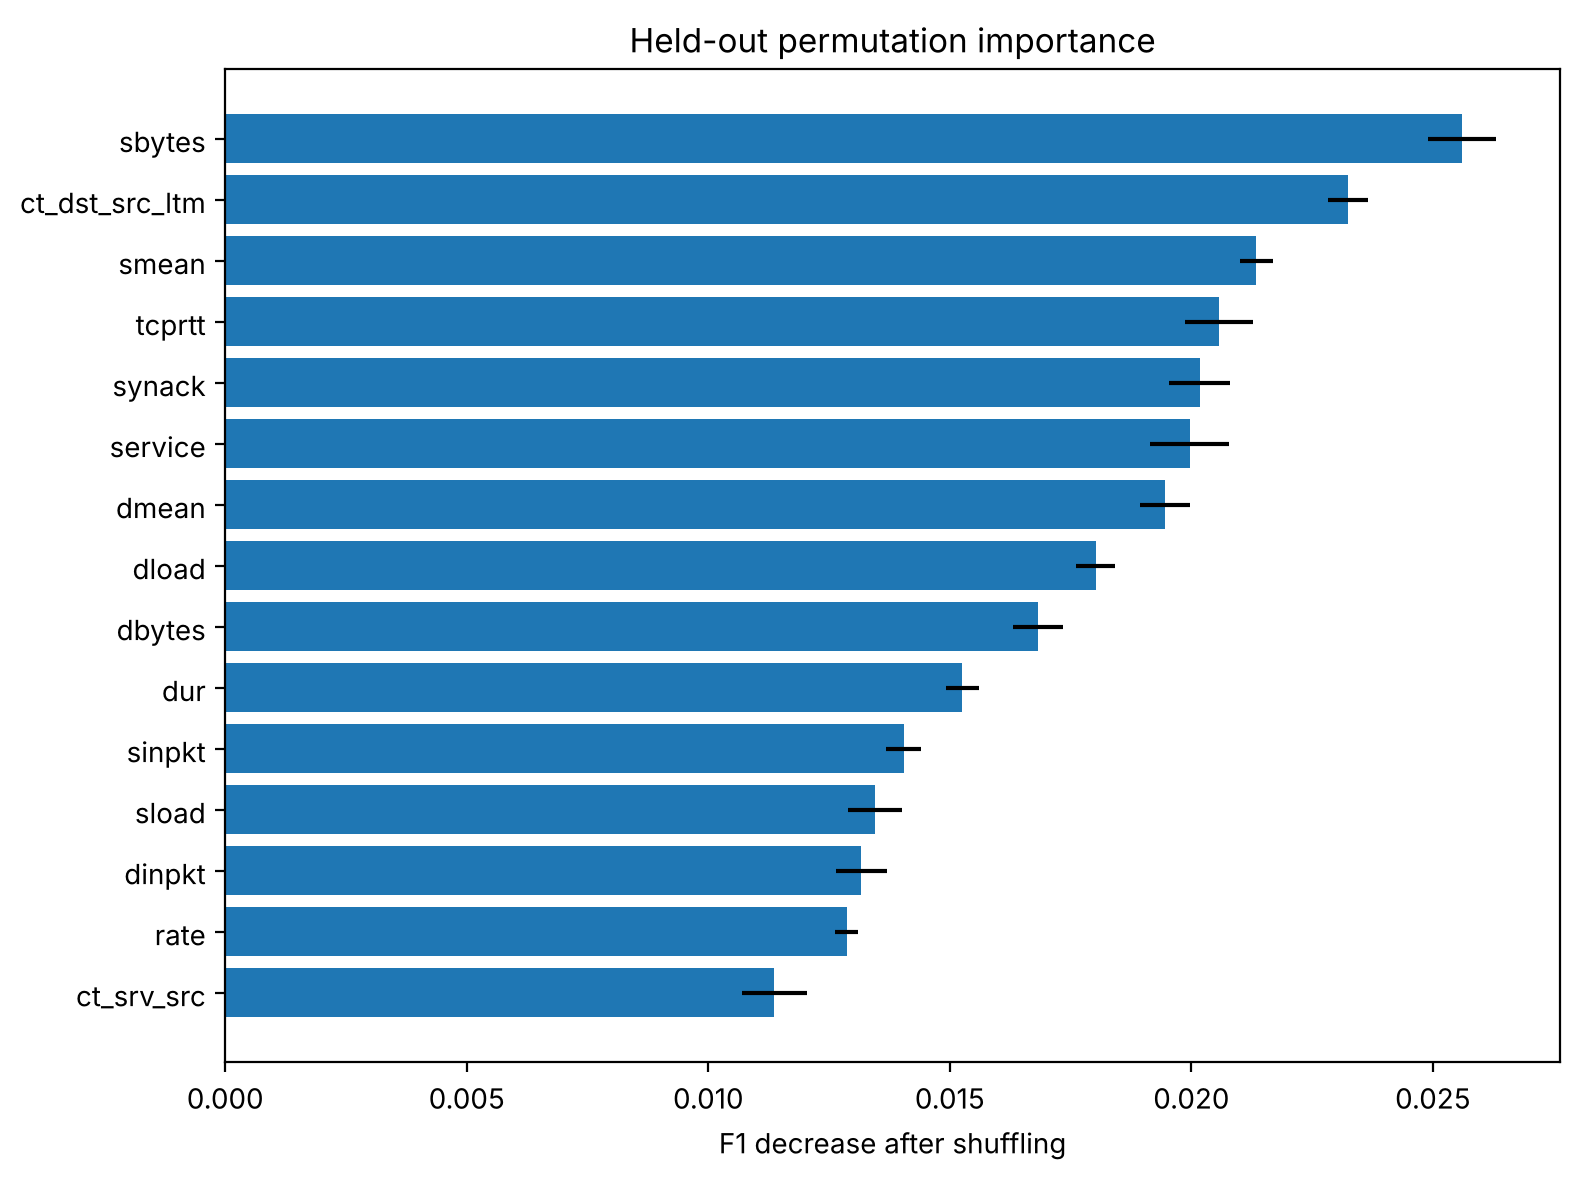

In [4]:
top = f1_importance.head(15).sort_values("importance_mean")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(
    top["feature"],
    top["importance_mean"],
    xerr=top["importance_std"],
)
ax.set_xlabel("F1 decrease after shuffling")
ax.set_title("Held-out permutation importance")
plt.tight_layout()
plt.show()

In [5]:
recall_importance = permutation_importance_frame(
    model,
    X_test,
    y_test,
    scoring="recall",
    n_repeats=5,
    random_state=42,
    max_samples=0.25,
)

comparison = (
    f1_importance[["feature", "importance_mean"]]
    .rename(columns={"importance_mean": "f1_importance"})
    .merge(
        recall_importance[["feature", "importance_mean"]]
        .rename(columns={"importance_mean": "recall_importance"}),
        on="feature",
        how="outer",
    )
    .fillna(0)
)

display(
    comparison
    .sort_values("recall_importance", ascending=False)
    .head(20)
    .round(5)
)

,feature,f1_importance,recall_importance
19,dttl,-0.00756,0.00804
37,sttl,0.00667,0.00276
3,ct_dst_src_ltm,0.02324,0.00255
10,ct_state_ttl,0.00124,0.00158
38,swin,0.00358,0.00095
21,dwin,0.00203,0.00069
23,is_sm_ips_ports,0.00216,0.00056
22,is_ftp_login,0.00217,0.00053
5,ct_ftp_cmd,0.00212,0.00053
26,response_body_len,0.00991,0.00035


## Step 2: Local explanation for one alert

Global importance cannot tell an analyst why *this* event was flagged. A simple local method that works with any model is **occlusion**: replace one feature at a time with a neutral reference value (training median or most common category) and measure how much the attack score drops.

A large drop means the score for this event depended on that value.

In [6]:
from src.explainability import (
    reference_row,
    local_occlusion_explanation,
    alert_explanation_sentence,
)

reference = reference_row(X_train)

test_scores = model.predict_proba(X_test)[:, 1]
attack_categories = test["attack_cat"].reset_index(drop=True)

# Pick one confidently detected Reconnaissance event to explain.
candidates = [
    i for i in range(len(X_test))
    if attack_categories[i] == "Reconnaissance" and test_scores[i] >= 0.9
]
alert_index = candidates[0]

base_score, local = local_occlusion_explanation(
    model,
    X_test.iloc[alert_index],
    reference,
)

print("Alert score:", round(base_score, 3))
display(local.head(10).round(4))

Alert score: 0.992


,feature,event_value,reference_value,score_without_feature,score_drop
0,proto,ospf,tcp,0.848,0.144
1,ct_state_ttl,2,1.0,0.888,0.104
2,dpkts,0,2.0,0.928,0.064
3,sjit,52.253805,0.0,0.932,0.060
4,dur,0.921987,0.001582,0.940,0.052
5,dbytes,0,164.0,0.944,0.048
6,spkts,20,2.0,0.952,0.040
7,rate,20.607666,3225.80652,0.964,0.028
8,sload,10551.125,879674.75,0.972,0.020
9,ct_srv_src,1,5.0,0.972,0.020


## Step 3: Turn the explanation into an analyst sentence

A useful alert says what was predicted, how strongly, which signals mattered, and what to check next. The ATT&CK-style context is a hypothesis, not a finding.

In [7]:
sentence = alert_explanation_sentence(
    base_score,
    local,
    threshold=0.5,
    top_n=3,
    context_hint="reconnaissance-like behavior",
)
print(sentence)

Predicted attack (score 0.99). Signals the model relied on: proto=ospf, ct_state_ttl=2, dpkts=0. Consistent with reconnaissance-like behavior, not proof of it. Validate with related telemetry before acting.


## Step 4: Does local agree with global?

Compare the top local drivers for several alerts with the global ranking. Disagreement is normal: global importance averages over many events, local explanation describes one.

In [8]:
import pandas as pd

rows = []
for category in ["Reconnaissance", "DoS", "Exploits", "Fuzzers", "Generic"]:
    idx = [
        i for i in range(len(X_test))
        if attack_categories[i] == category and test_scores[i] >= 0.9
    ]
    if not idx:
        continue
    score, frame = local_occlusion_explanation(model, X_test.iloc[idx[0]], reference)
    rows.append({
        "attack_cat": category,
        "alert_score": round(score, 3),
        "top_local_drivers": ", ".join(frame["feature"].head(3)),
    })

local_summary = pd.DataFrame(rows)
display(local_summary)
print("Top global features:", ", ".join(f1_importance["feature"].head(5)))

,attack_cat,alert_score,top_local_drivers
0,Reconnaissance,0.992,"proto, ct_state_ttl, dpkts"
1,DoS,0.992,"proto, ct_state_ttl, dpkts"
2,Exploits,0.976,"proto, rate, ct_state_ttl"
3,Fuzzers,1.000,"proto, ct_state_ttl, sjit"
4,Generic,1.000,"service, ct_state_ttl, proto"


Top global features: sbytes, ct_dst_src_ltm, smean, tcprtt, synack


## Security interpretation

For the top global features, ask:
- what telemetry does the feature represent?
- could an attacker influence it?
- would it remain available in production?
- could correlated features share the same signal?
- does importance change when scoring recall instead of F1?

For the local explanation:
- would an analyst understand the sentence in ten seconds?
- does the explanation point to telemetry they can actually check?
- why is "consistent with reconnaissance" weaker than "is reconnaissance", and why is that the honest wording?

**Takeaway:** explainability shows what the model relied on. It never replaces evaluation, and it never proves the cause of an attack.

## From lab to SOC

Explanations shorten triage. An analyst who sees "flagged because of 2 packets out, 0 back, to 200 hosts" can confirm a scan in seconds. But explanations describe the *model*, not the attacker: they point to where to look, and they never replace the investigation.

**Check yourself**
1. Rewrite "Malicious traffic detected" as an alert sentence an analyst could act on.
2. Why can the same top feature appear for both a DoS and a reconnaissance alert?
3. Why is "consistent with reconnaissance" the honest wording, rather than "this is reconnaissance"?